# Imports

In [1]:
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.decomposition import PCA

from methods.bcgd_gauss_southwell import gs_bcgd
from methods.bcgd_randomized import randomized_bcgd
from methods.gradient_descent import gradient_descent
from methods.utils.accuracy import accuracy
from methods.utils.block_size import block_step_size
from methods.utils.gradient import MultiLogisticRegressionOracle, CachedMultiLogisticRegressionOracle
from methods.utils.results import accuracy_vs_CPU

rng = np.random.default_rng(seed=42) # Turnoff or modify if no seeding will be used.

I0000 00:00:1777302906.352313    2748 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1777302908.679748    2748 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1777302916.455980    2748 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


# Data Loading

## Synthetic Data

In [2]:
n_categories = 50
n_features = 500
n_examples = 1000

syntetic_features = rng.random((n_examples, n_features))
X = rng.random((n_features, n_categories))
E = rng.random((n_examples, n_categories))

transformation = np.dot(syntetic_features,X) + E
syntetic_labels = np.argmax(transformation, axis= 1)

syntetic_test_features = rng.random((n_examples, n_features))
test_transformation = np.dot(syntetic_features,X) + E
syntetic_test_labels = np.argmax(test_transformation, axis= 1)

syntetic_data = {
    "n_categories": n_categories,
    "n_features": n_features,
    "train_features": syntetic_features,
    "train_labels": syntetic_labels,
    "test_features": syntetic_test_features,
    "test_labels": syntetic_test_labels,
    "tolerance": 1.0,
}

## MNIST Dataset

In [ ]:
n_components = 50
(mnist_features, mnist_labels), (mnist_features_test, mnist_labels_test) = mnist.load_data()

mnist_features = mnist_features.reshape((mnist_features.shape[0],-1))
mnist_features_test = mnist_features_test.reshape((mnist_features_test.shape[0],-1))

pca = PCA(n_components=n_components) # Keep 2 components
mnist_reduced_features = pca.fit_transform(mnist_features)
mnist_reduced_features_test = pca.transform(mnist_features_test)

mnist_data = {
    "n_categories": 10,
    "n_features": n_components,
    "train_features": mnist_reduced_features,
    "train_labels": mnist_labels,
    "test_features": mnist_reduced_features_test,
    "test_labels": mnist_labels_test,
    "tolerance": 1e-5,
}

## Bloodcell Dataset

(60000, 784)

# Method Calls
This section is for implementing all the methods that will be used for generating graphs or any other types of solutions

In [3]:
active_data = syntetic_data

#calculated step sizes
step_sizes = block_step_size(active_data["train_features"])

oracle = MultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])
cached_oracle = CachedMultiLogisticRegressionOracle(active_data["train_features"], active_data["train_labels"], active_data["n_categories"])

## Gradient Descent

In [4]:
gradient_descent_results = gradient_descent(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    0.001,  # Reduced step size to prevent NaN
    tol=active_data["tolerance"],
    debug=True,
)

Iteration 500: Loss = 30.417784037552337, sequential distance: 0.025989196368741495, Accuracy = 0.996
Iteration 1000: Loss = 7.501471495230362, sequential distance: 0.002902928335417074, Accuracy = 1.0
Iteration 1500: Loss = 4.993564833646815, sequential distance: 0.0017479511561320161, Accuracy = 1.0
Iteration 2000: Loss = 3.8789615245186724, sequential distance: 0.0012808209789451957, Accuracy = 1.0
Iteration 2500: Loss = 3.2260674296776415, sequential distance: 0.001021891582945885, Accuracy = 1.0


In [5]:
gradient_descent_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gradient_descent_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], gradient_descent_results["x_k"])

np.float64(0.266)

## BCGD Randomized

In [7]:
randomized_bcgd_results = randomized_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    oracle,
    step_sizes,
    tol=active_data["tolerance"]*0.01,
    debug=True,
)

iteration: 0, sequential distance: 2.747429581093127, loss: 3316.789459378397
accuracy: 0.355
iteration: 500, sequential distance: 0.07750278475625978, loss: 1416.8042673810514
accuracy: 0.555
iteration: 1000, sequential distance: 0.042808556373144145, loss: 1102.307685466355
accuracy: 0.661
iteration: 1500, sequential distance: 0.0970570015834379, loss: 882.0334489302431
accuracy: 0.744
iteration: 2000, sequential distance: 0.06838389808398264, loss: 735.246259539339
accuracy: 0.807
iteration: 2500, sequential distance: 0.03826603490146499, loss: 619.7849285447892
accuracy: 0.861
iteration: 3000, sequential distance: 0.04726588434879347, loss: 531.7475836263238
accuracy: 0.899
iteration: 3500, sequential distance: 0.03315739745468458, loss: 460.6464294561738
accuracy: 0.93
iteration: 4000, sequential distance: 0.036323699591061145, loss: 405.68702847425266
accuracy: 0.954
iteration: 4500, sequential distance: 0.027607038199244892, loss: 359.38541060635544
accuracy: 0.97
iteration: 500

In [8]:
randomized_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in randomized_bcgd_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], randomized_bcgd_results["x_k"])

np.float64(0.285)

## Gauss-Southwell BCGD

In [10]:
gs_bcgd_results = gs_bcgd(
    np.zeros((active_data["n_features"], active_data["n_categories"])),
    cached_oracle,
    step_sizes,
    tol=active_data["tolerance"]*0.01,
    debug=True,
)

iteration: 500, selected_block: 41, sequential distance: 0.10711647023247274, loss: 2054.205960
accuracy: 47.50%
iteration: 1000, selected_block: 440, sequential distance: 0.08684171997001341, loss: 1721.418999
accuracy: 57.80%
iteration: 1500, selected_block: 347, sequential distance: 0.058969405709355764, loss: 1503.153353
accuracy: 62.60%
iteration: 2000, selected_block: 452, sequential distance: 0.053141834574707544, loss: 1335.757124
accuracy: 66.70%
iteration: 2500, selected_block: 423, sequential distance: 0.04272312865271851, loss: 1204.125872
accuracy: 69.20%
iteration: 3000, selected_block: 178, sequential distance: 0.04047772141356381, loss: 1096.208687
accuracy: 72.30%
iteration: 3500, selected_block: 129, sequential distance: 0.03488871107956419, loss: 1007.203732
accuracy: 76.30%
iteration: 4000, selected_block: 48, sequential distance: 0.03113355845858393, loss: 931.926183
accuracy: 77.40%
iteration: 4500, selected_block: 349, sequential distance: 0.029071656612652944, l

In [ ]:
gs_bcgd_results["accuracies"] = [
    accuracy(oracle.predictors, oracle.predictions, x)
    for x in gs_bcgd_results["history"]
]

accuracy(active_data["test_features"],active_data["test_labels"], gs_bcgd_results["x_k"])

np.float64(0.173)

In [14]:
accuracy(active_data["train_features"],active_data["train_labels"], gs_bcgd_results["x_k"])

np.float64(0.893)

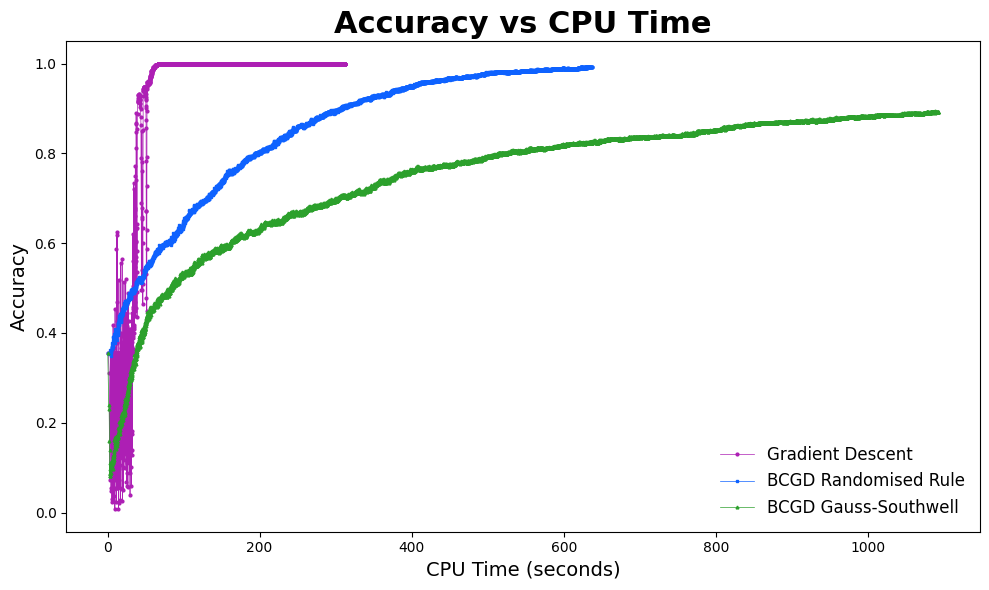

In [13]:
plotting_data = {
    "Gradient Descent": (gradient_descent_results["times"], gradient_descent_results["accuracies"]),
    "BCGD Randomised Rule": (randomized_bcgd_results["times"], randomized_bcgd_results["accuracies"]),
    "BCGD Gauss-Southwell": (gs_bcgd_results["times"], gs_bcgd_results["accuracies"]),
}

accuracy_vs_CPU(plotting_data)